# Data Visualization: Antibiotic Resistance Trend Predictor



##
**Question for this project:** which bacteria-antibiotic combinations have high resistance, and which are getting worse?

In [2]:
import sys
sys.path.insert(0, "../src")
import matplotlib.pyplot as plt
import charts as c
import viz_utils as vu

trends = vu.load_trends()
print(trends.shape)
trends.head()

(466, 16)


,organism,antibiotic,year,susceptible_n,tested_n,susceptible_pct,source_report_year,source_table,source_url,extracted_date,reported_pct,computed_pct,flags,organism_short,gram,resistant_pct
0,MRSA,cotrimoxazole,2023,2792,4311,64.8,2023,Table 7.9,https://www.icmr.gov.in/icmrobject/uploads/Doc...,2026-08-26,64.8,64.76,NaN,MRSA,Gram-positive,35.2
1,MRSA,cotrimoxazole,2017,851,1332,63.9,2023,Table 7.9,https://www.icmr.gov.in/icmrobject/uploads/Doc...,2026-08-26,63.9,63.89,NaN,MRSA,Gram-positive,36.1
2,MRSA,cotrimoxazole,2018,1701,3006,56.6,2023,Table 7.9,https://www.icmr.gov.in/icmrobject/uploads/Doc...,2026-08-26,56.6,56.59,NaN,MRSA,Gram-positive,43.4
3,MRSA,cotrimoxazole,2019,3127,4848,64.5,2023,Table 7.9,https://www.icmr.gov.in/icmrobject/uploads/Doc...,2026-08-26,64.5,64.50,NaN,MRSA,Gram-positive,35.5
4,MRSA,cotrimoxazole,2020,1484,2449,60.6,2023,Table 7.9,https://www.icmr.gov.in/icmrobject/uploads/Doc...,2026-08-26,60.6,60.60,NaN,MRSA,Gram-positive,39.4


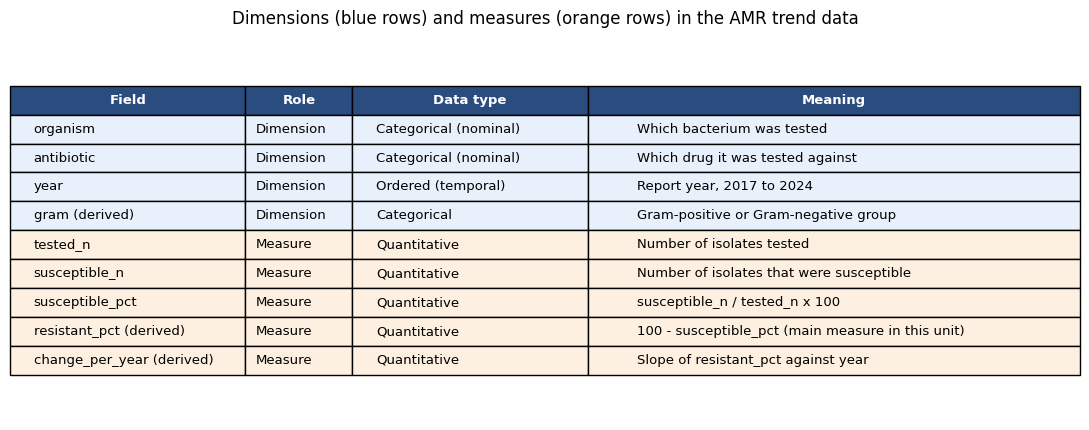

organism                  str
antibiotic                str
year                    int64
susceptible_n           int64
tested_n                int64
susceptible_pct       float64
source_report_year      int64
source_table              str
source_url                str
extracted_date            str
reported_pct          float64
computed_pct          float64
flags                 float64
organism_short            str
gram                      str
resistant_pct         float64
dtype: object

In [3]:
c.fig_dimensions_measures()
plt.show()
trends.dtypes

## Bar chart


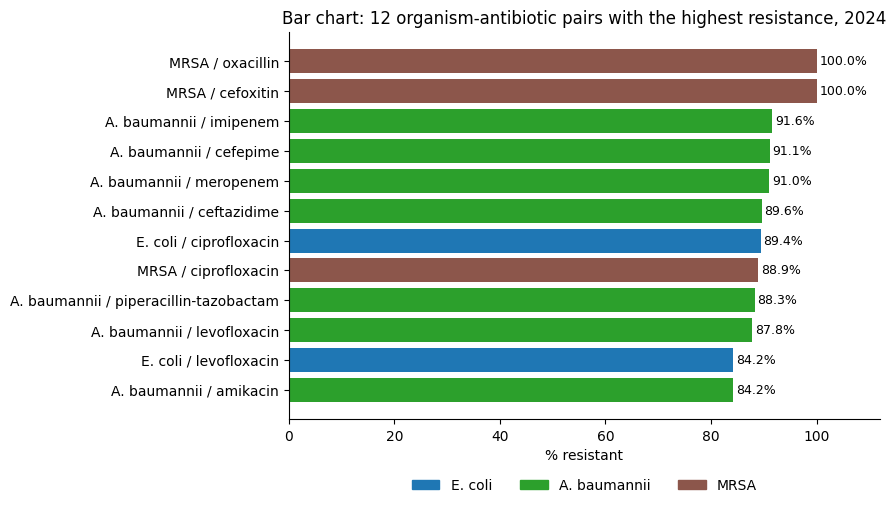

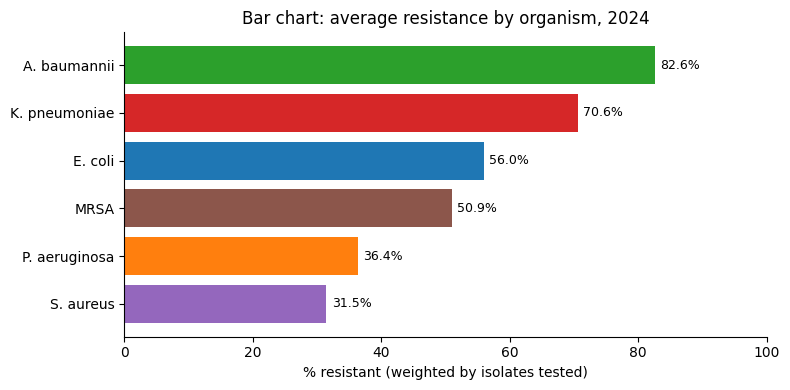

In [13]:
c.fig_bar_highest_resistance(trends, year=2024, n=12)
plt.show()
c.fig_bar_by_organism(trends, year=2024)
plt.show()

**Finding:** in 2024 *A. baumannii* has the highest resistance (imipenem 91.6%, cefepime 91.1%, meropenem 91.0%). MRSA with oxacillin and cefoxitin is 100% resistant by definition.

## Line chart


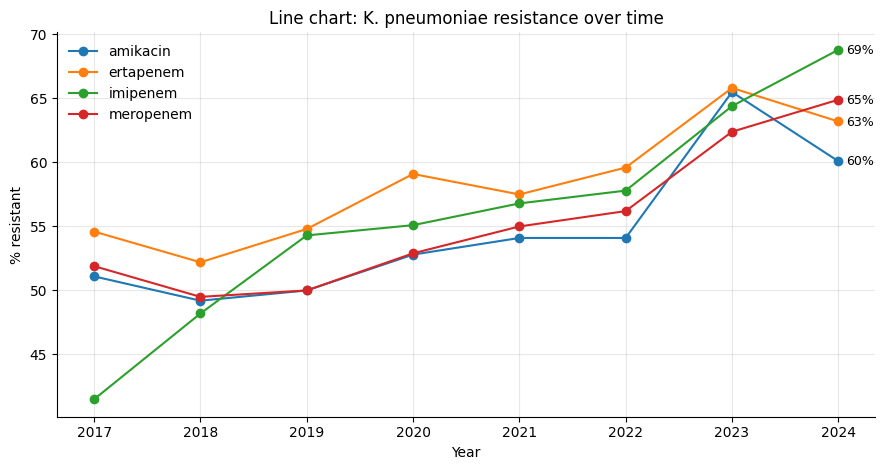

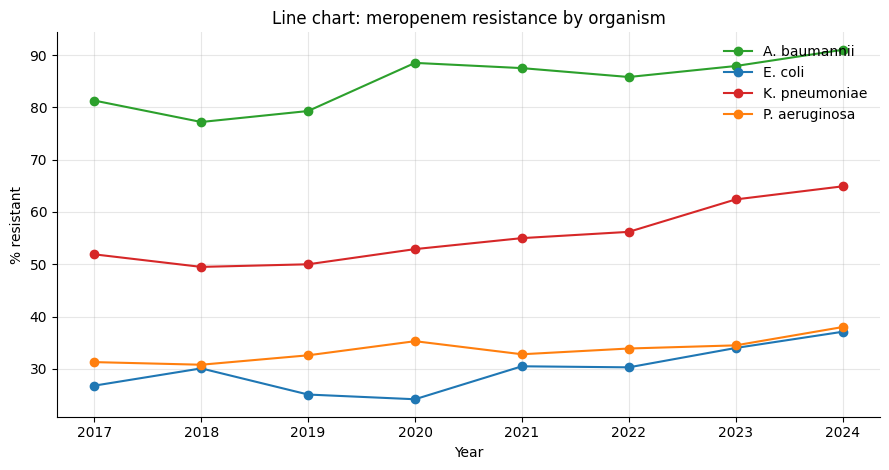

In [5]:
c.fig_line_pair(trends)
plt.show()
c.fig_line_organisms(trends, "meropenem")
plt.show()

**Finding:** *K. pneumoniae* meropenem resistance rose from 51.9% (2017) to 64.9% (2024).

## Table


In [6]:
rt = c.risk_table(trends).round(1)
rt[rt["Latest %"] <= 50].sort_values("Change per year (pts)", ascending=False).head(10)

,Organism,Antibiotic,First year %,Latest %,Change per year (pts),Tested (latest)
13,E. coli,imipenem,18.6,42.4,2.6,11662
53,S. aureus,oxacillin,28.3,48.0,2.5,5910
42,P. aeruginosa,imipenem,26.4,43.1,1.7,10443
15,E. coli,meropenem,26.8,37.1,1.4,12061
8,E. coli,amikacin,20.8,27.5,1.3,12445
43,P. aeruginosa,levofloxacin,39.5,46.0,1.3,8407
12,E. coli,ertapenem,32.6,38.4,1.2,10484
40,P. aeruginosa,ciprofloxacin,42.2,43.0,0.9,11222
44,P. aeruginosa,meropenem,31.3,38.0,0.8,10857
49,S. aureus,clindamycin,22.6,27.3,0.7,8255


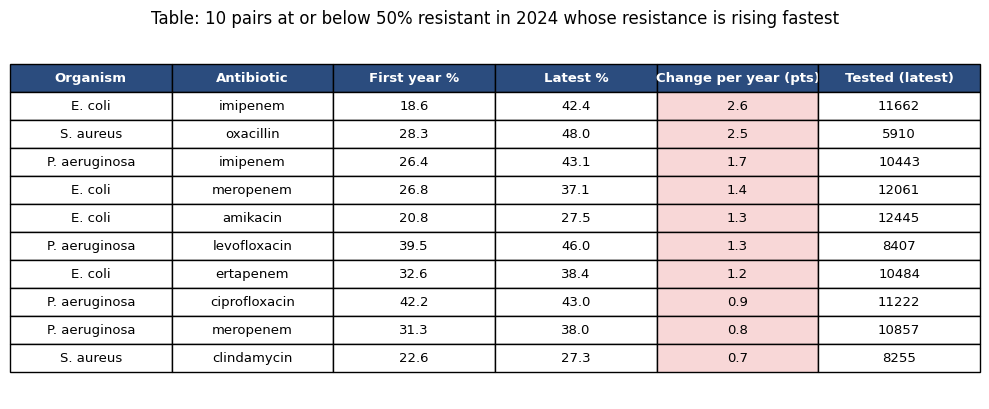

In [7]:
c.fig_table_rising(trends)
plt.show()

**Finding:** *E. coli* imipenem (18.6% to 42.4%) and *S. aureus* oxacillin (28.3% to 48.0%) are still at or below 50% but rising fastest.

##  Heat map


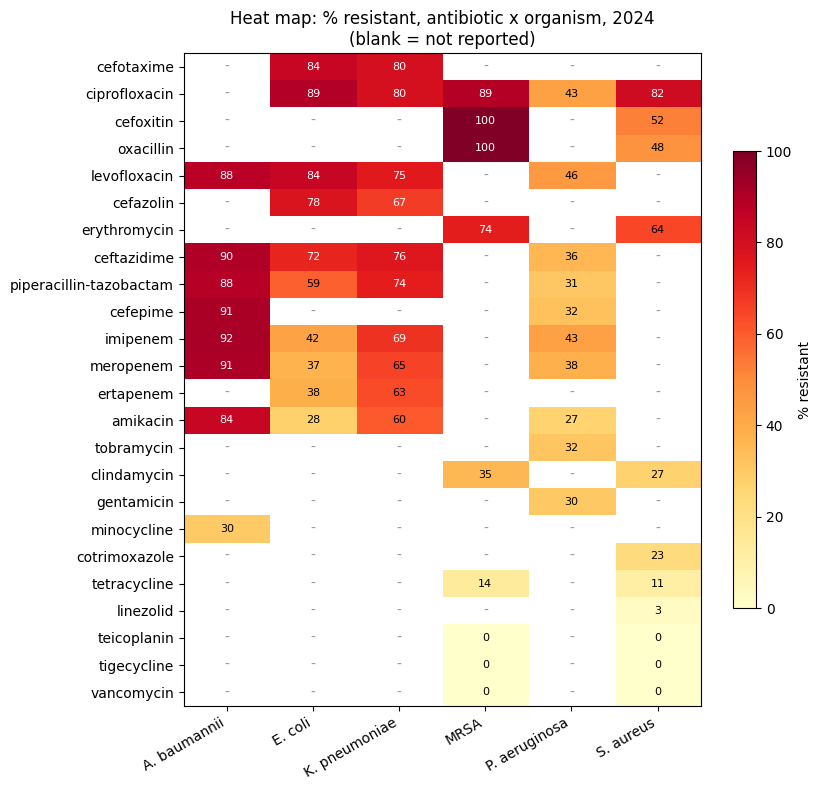

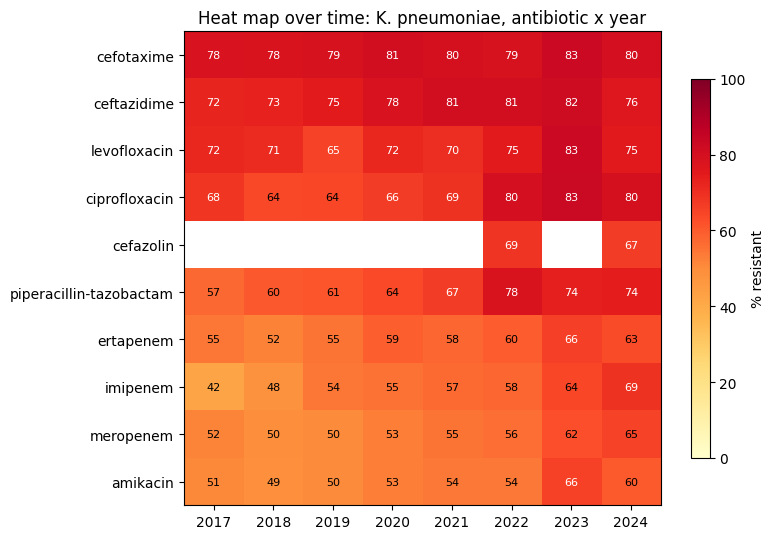

In [8]:
c.fig_heatmap(trends, 2024)
plt.show()
c.fig_heatmap_years(trends, "Klebsiella pneumoniae")
plt.show()

## Treemap


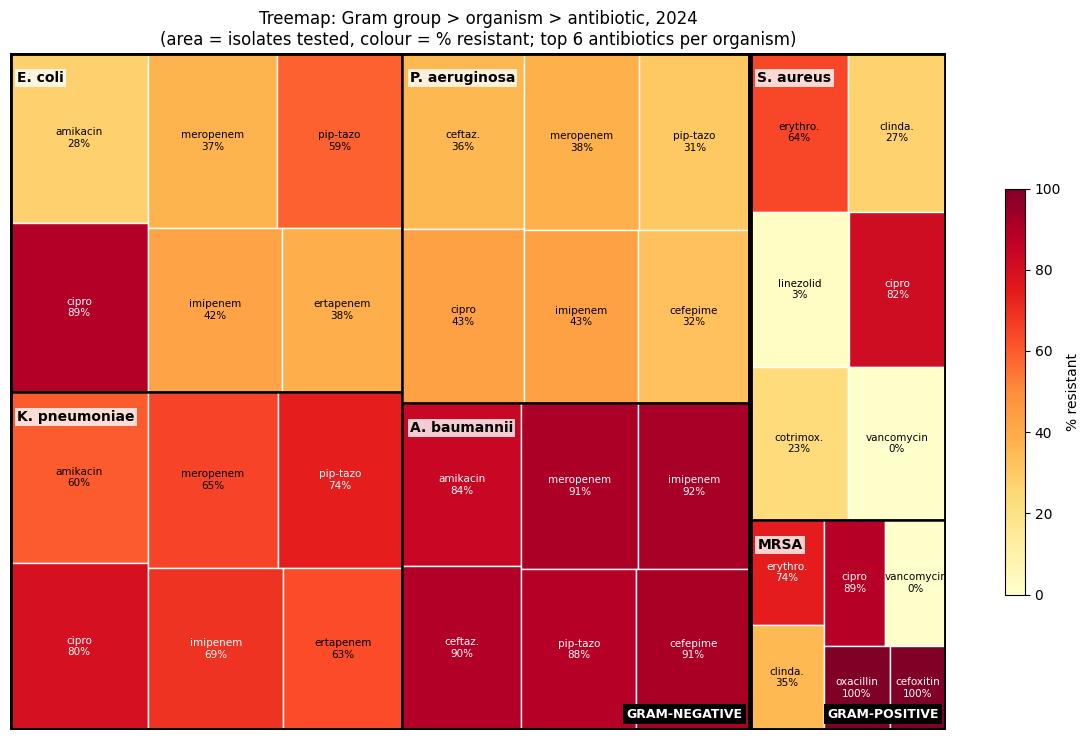

In [9]:
c.fig_treemap(trends, 2024, top_per_org=6)
plt.show()

##  Packed bubble


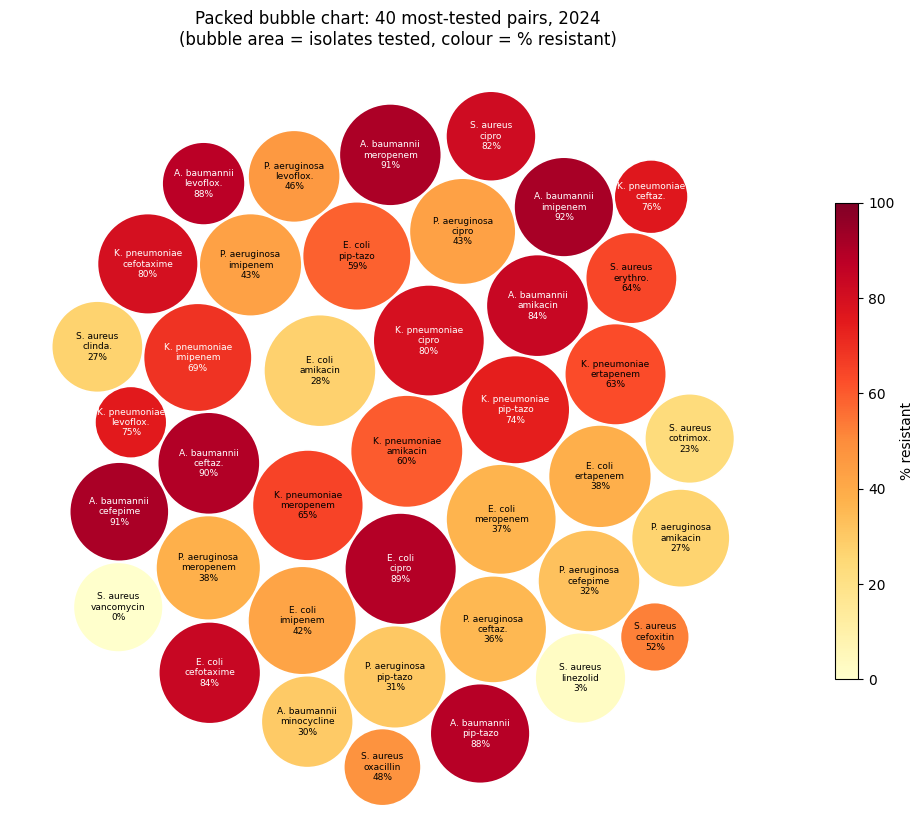

In [10]:
c.fig_packed_bubbles(trends, 2024, n=40)
plt.show()

## 9. Tooltip
A tooltip shows exact values when the pointer hovers over a mark. The interactive chart is `../outputs/charts/11_tooltip_interactive.html`: open it in a browser (no internet needed), pick an antibiotic, and hover over the points.

In [14]:
from IPython.display import IFrame
vu.tooltip_html(trends, vu.CHARTS / "11_tooltip_interactive.html")
IFrame("../outputs/charts/11_tooltip_interactive.html", width=900, height=620)

## 10. Violin plot
A violin shows how values are spread. Wide parts have more values, lines inside are the quartiles and dots are the individual values.

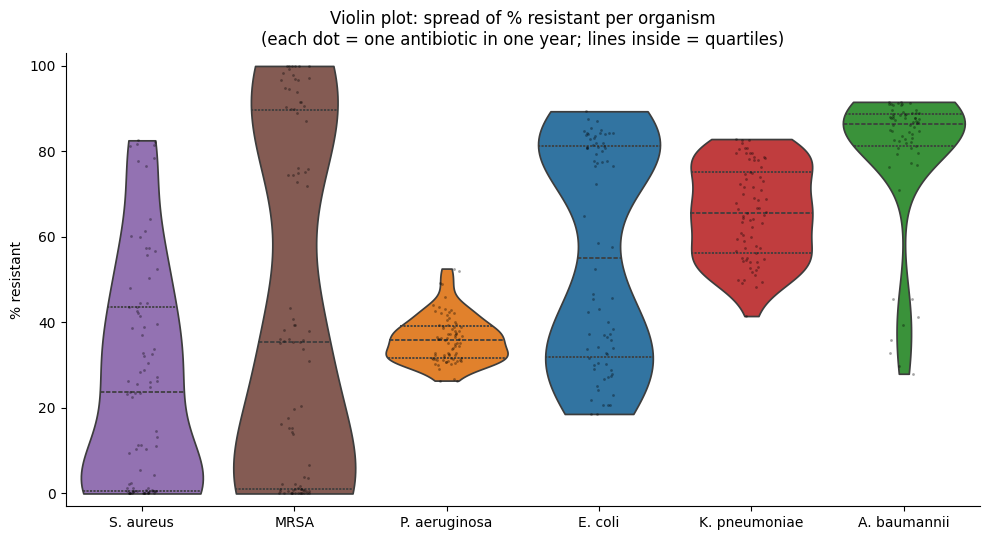

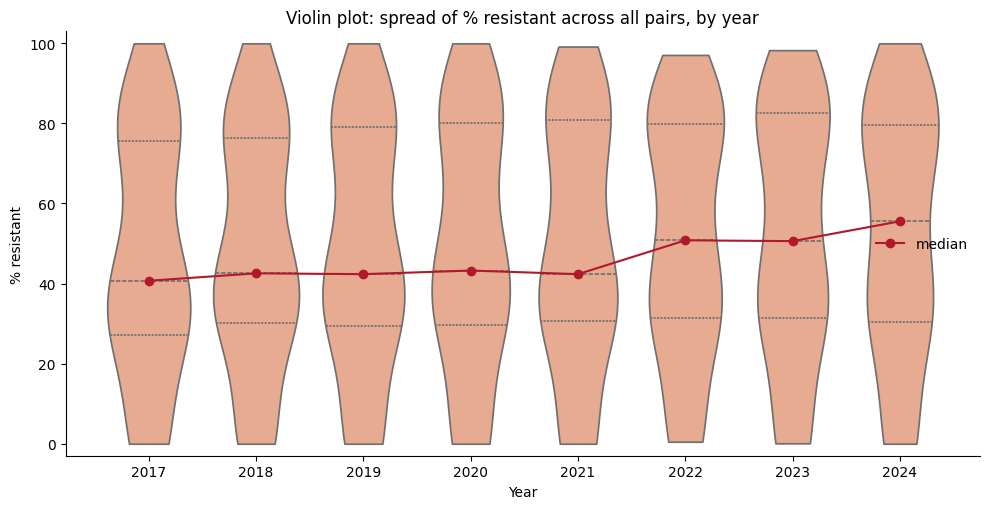

In [12]:
c.fig_violin_organism(trends)
plt.show()
c.fig_violin_year(trends)
plt.show()

**Finding:** *A. baumannii* is bunched near the top (median 86.4%), while MRSA and *E. coli* are spread widely, so their averages hide big differences between drugs. The median resistance of all pairs rose from 40.7% (2017) to 55.5% (2024).